# W1 — Feature contributions → changed predictions → human support

This companion reuses **all 544 completed validation cases** and the original held-out surrogate responses. It regenerates derived tables/figures without fitting TabICL, downloading weights or rerunning SHAP.

Read the feature definitions and signed contributions first, then the recorded feature-change results, and finally the practical human-support plan. You can choose any audited student with `CASE_ID` below.

The selection below is an **explanatory reporting panel**, not a new predictor input set or a causal intervention ranking. The original model's 33 inputs and original case JSON files remain unchanged.

To execute again, extract the complete full-audit ZIP. Its `03_Full_Audit/Code/topics` folder contains this code, and its `03_Full_Audit/Cases` folder contains the completed inputs. Saved outputs can be read without execution.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

bases = [Path.cwd(), *list(Path.cwd().parents)[:7]]
suffixes = ["03_Full_Audit/Code/topics", "Code/Student-Dropout-Risk/W1_Noey_Enhanced/topics",
            "Student Dropout Project/Code/Student-Dropout-Risk/W1_Noey_Enhanced/topics"]
TOPICS = next((base / suffix for base in bases for suffix in suffixes
               if (base / suffix / "run_all.py").is_file()), None)
if TOPICS is None:
    raise FileNotFoundError("Extract the full audit ZIP, or open this notebook from the cloned Student Dropout Project.")
sys.path.insert(0, str(TOPICS))
from run_all import run

analysis = run()  # saved-case post-processing only; no model or SHAP calls
assert len(analysis["inputs"].records) == 544
display(pd.DataFrame([{"Saved students": 544, "Model/SHAP rerun": False,
                       "Predictor inputs changed": False, "Selection scope": "Explanatory reporting only"}]).T)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 14, "font.size": 10})

,0
Saved students,544
Model/SHAP rerun,False
Predictor inputs changed,False
Selection scope,Explanatory reporting only


## W1.1 — Local explanations and coverage

All 27 semantic groups cover all 544 students. Grouped SHAP is a contribution to the model prediction relative to its background, not a cause of dropout. The table retains original group members so the reporting panel is traceable to the model columns.

In [2]:
guide = analysis["local"]["feature_dictionary"]
assert len(guide) == 33 and guide.feature_group.nunique() == 27
display(HTML("<style>.w1-readable td{white-space:normal;max-width:360px;vertical-align:top}</style>" +
    "<details open><summary><b>All 33 model inputs: meaning, contribution availability and action context</b></summary>" +
    guide.to_html(index=False, classes="w1-readable", escape=True) + "</details>"))

model_column,feature_group,meaning,action_context,attribution_available
curricular_units_1st_sem_approved,first_semester_progress,First-semester curricular units passed,Historical academic record,Group total only; individual member SHAP not saved
curricular_units_1st_sem_grade,first_semester_progress,First-semester average grade (0–20),Historical academic record,Group total only; individual member SHAP not saved
first_semester_pass_rate,first_semester_progress,Approved / enrolled units; zero when enrollment is zero,Derived; recompute from source units,Group total only; individual member SHAP not saved
curricular_units_1st_sem_enrolled,first_semester_participation,Number of first-semester curricular units enrolled,Historical enrollment record,Group total only; individual member SHAP not saved
curricular_units_1st_sem_evaluations,first_semester_participation,Number of first-semester evaluations recorded,Historical assessment record; not classroom attendance,Group total only; individual member SHAP not saved
curricular_units_1st_sem_without_evaluations,first_semester_participation,First-semester units without evaluations,Historical assessment record,Group total only; individual member SHAP not saved
first_semester_no_enrollment,first_semester_participation,Indicator that first-semester enrollment is zero,Derived; recompute from enrollment,Group total only; individual member SHAP not saved
first_semester_no_evaluations,first_semester_participation,Indicator that first-semester evaluation count is zero,Derived; recompute from evaluations,Group total only; individual member SHAP not saved
tuition_fees_up_to_date,tuition_fees_up_to_date,"Tuition fees up to date: 1=yes, 0=no",Administrative status; verify balance and assistance options,Individual feature (singleton group)
debtor,debtor,"Recorded debtor status: 1=yes, 0=no",Administrative status; verify with finance office,Individual feature (singleton group)


### W1.1 — Strength across students and direction for one student

Mean absolute SHAP measures importance across 544 students. It does not mean a feature always increases risk. For the selected student, **positive signed SHAP raises** the model probability relative to its training background and **negative signed SHAP lowers** it. A contribution of +0.03 is +3 percentage points in this explanation; changing that input does not necessarily reduce the probability by 3 points.

The original record saved 27 group totals for 33 inputs. Progress has three members and participation has five; their individual member contributions were not saved. No member-level numbers are invented. Participation uses enrollment/evaluation records, not measured classroom attendance.

In [3]:
feature_summary = analysis["local"]["feature_summary"]
display(feature_summary[["feature_group", "mean_absolute_group_shap", "mean_signed_group_shap",
                         "fraction_raising_prediction", "fraction_lowering_prediction"]].head(10))

,feature_group,mean_absolute_group_shap,mean_signed_group_shap,fraction_raising_prediction,fraction_lowering_prediction
13,first_semester_progress,0.276915,0.016900,0.430147,0.569853
12,first_semester_participation,0.052526,0.000904,0.555147,0.444853
25,tuition_fees_up_to_date,0.051317,-0.004326,0.156250,0.843750
4,course,0.041828,-0.021924,0.266544,0.733456
24,scholarship_holder,0.019297,-0.003059,0.750000,0.250000
15,gender,0.017246,-0.004152,0.386029,0.613971
7,debtor,0.017214,0.001972,0.113971,0.886029
8,displaced,0.013639,-0.002305,0.558824,0.441176
26,unemployment_rate,0.010757,0.001102,0.588235,0.411765
23,previous_qualification_grade,0.009812,-0.004917,0.316176,0.683824


**Student source-row 174** · Recorded dropout probability: **99.58%** · Outreach flag: True. This ID was chosen by source order among flagged cases, without selecting on the outcome label.

feature_group,members,contribution_percentage_points,direction,attribution_level
first_semester_progress,"curricular_units_1st_sem_approved, curricular_units_1st_sem_grade, first_semester_pass_rate",27.381,Raises this predicted probability,Group total; member values not saved
tuition_fees_up_to_date,tuition_fees_up_to_date,14.181,Raises this predicted probability,Individual feature
debtor,debtor,6.375,Raises this predicted probability,Individual feature
first_semester_participation,"curricular_units_1st_sem_enrolled, curricular_units_1st_sem_evaluations, curricular_units_1st_sem_without_evaluations, first_semester_no_enrollment, first_semester_no_evaluations",4.206,Raises this predicted probability,Group total; member values not saved
course,course,2.031,Raises this predicted probability,Individual feature
gender,gender,-0.892,Lowers this predicted probability,Individual feature
mothers_qualification,mothers_qualification,0.634,Raises this predicted probability,Individual feature
admission_grade,admission_grade,0.612,Raises this predicted probability,Individual feature
inflation_rate,inflation_rate,0.573,Raises this predicted probability,Individual feature
gdp,gdp,0.527,Raises this predicted probability,Individual feature


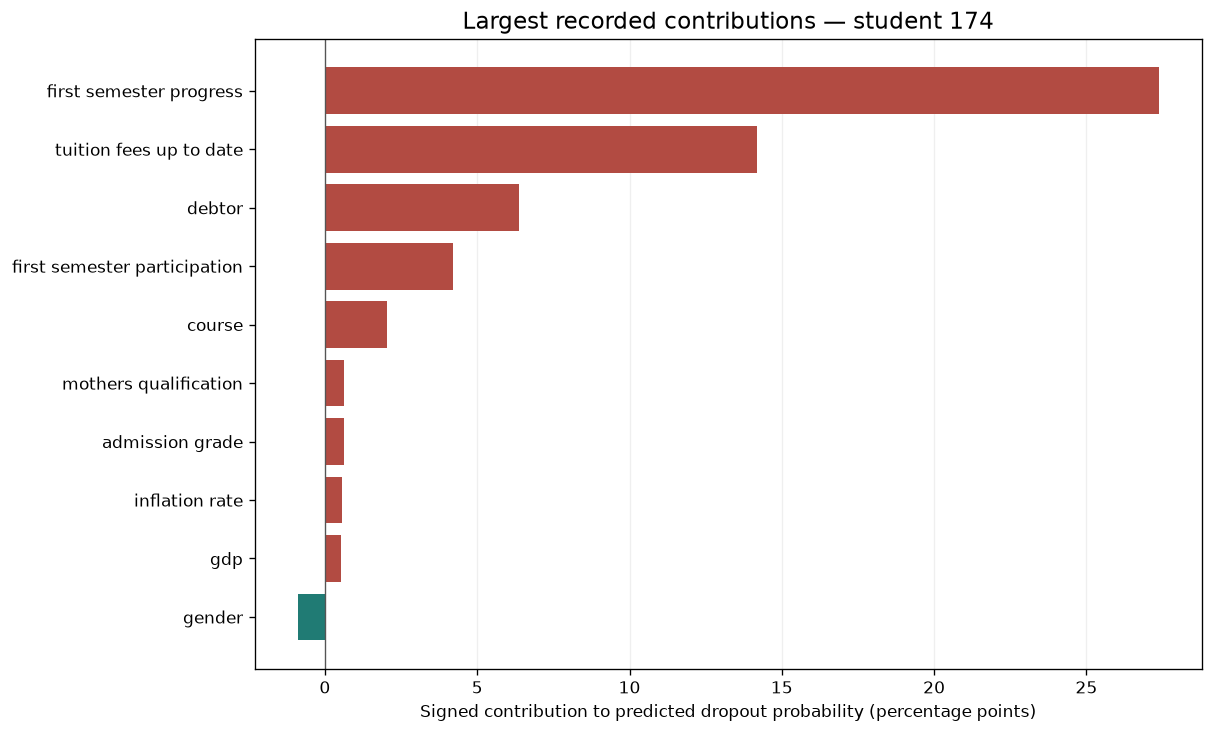

In [4]:
from w1_1_local_explanations.feature_guide import explain_case

CASE_ID = None  # Set an audited source_row_id, e.g. 174. None = first flagged ID in source order.
records = analysis["inputs"].records
selected_case = (next(c for c in records if c["flagged"]) if CASE_ID is None else
                 next(c for c in records if c["source_row_id"] == CASE_ID))
CASE_ID = selected_case["source_row_id"]
contributions = explain_case(selected_case)
display(Markdown(f"**Student source-row {CASE_ID}** · Recorded dropout probability: "
                 f"**{selected_case['predicted_probability']:.2%}** · Outreach flag: {bool(selected_case['flagged'])}. "
                 "This ID was chosen by source order among flagged cases, without selecting on the outcome label."))
display(HTML(contributions[["feature_group", "members", "contribution_percentage_points", "direction", "attribution_level"]]
             .round(3).to_html(index=False, classes="w1-readable", escape=True)))
shown = contributions.head(10).sort_values("signed_shap")
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
values = shown.contribution_percentage_points
ax.barh(shown.feature_group.str.replace("_", " "), values,
        color=["#b24b42" if v > 0 else "#207b74" for v in values])
ax.axvline(0, color="#555555", linewidth=.8)
ax.set_title(f"Largest recorded contributions — student {CASE_ID}")
ax.set_xlabel("Signed contribution to predicted dropout probability (percentage points)")
ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True)
fig.savefig(TOPICS / "w1_1_local_explanations/results/selected_case_contributions.png", dpi=160, bbox_inches="tight")
plt.show()

## W1.2 — Main-only versus pair-augmented approximation

The six existing surrogates were fitted on 24 masks and scored on eight separate masks per student. No fits are repeated here. Positive main-minus-pair MAE favors paired terms. The 95% intervals resample students, preserving their within-student masking dependence; they are descriptive per-family intervals.

These errors measure approximation of TabICL under masking. They are not dropout prediction accuracy or intervention effects.

,variant,students,pooled_holdout_mae,median_case_mae,mean_case_rmse,mean_nonzero_terms,mean_out_of_range_fraction
1,Lasso+pairs,544,0.022394,0.009398,0.027601,9.884191,0.031939
5,Ridge+pairs,544,0.025144,0.011573,0.030069,13.455882,0.044807
3,OLS+pairs,544,0.025864,0.011357,0.030732,13.242647,0.048713
2,OLS+main,544,0.071530,0.050606,0.080145,4.948529,0.047105
4,Ridge+main,544,0.072764,0.051472,0.084928,4.948529,0.036305
0,Lasso+main,544,0.073126,0.052614,0.084152,3.738971,0.038143


,family,students_compared,main_only_mae,with_pairs_mae,mean_mae_reduction,ci_lower_95,ci_upper_95,pair_win_fraction,pair_tie_fraction,relative_mae_reduction_pct
0,OLS,544,0.071530,0.025864,0.045666,0.041369,0.050103,0.906250,0.009191,63.842145
1,Ridge,544,0.072764,0.025144,0.047620,0.043379,0.052064,0.917279,0.000000,65.444016
2,Lasso,544,0.073126,0.022394,0.050732,0.046643,0.054997,0.952206,0.009191,69.375716


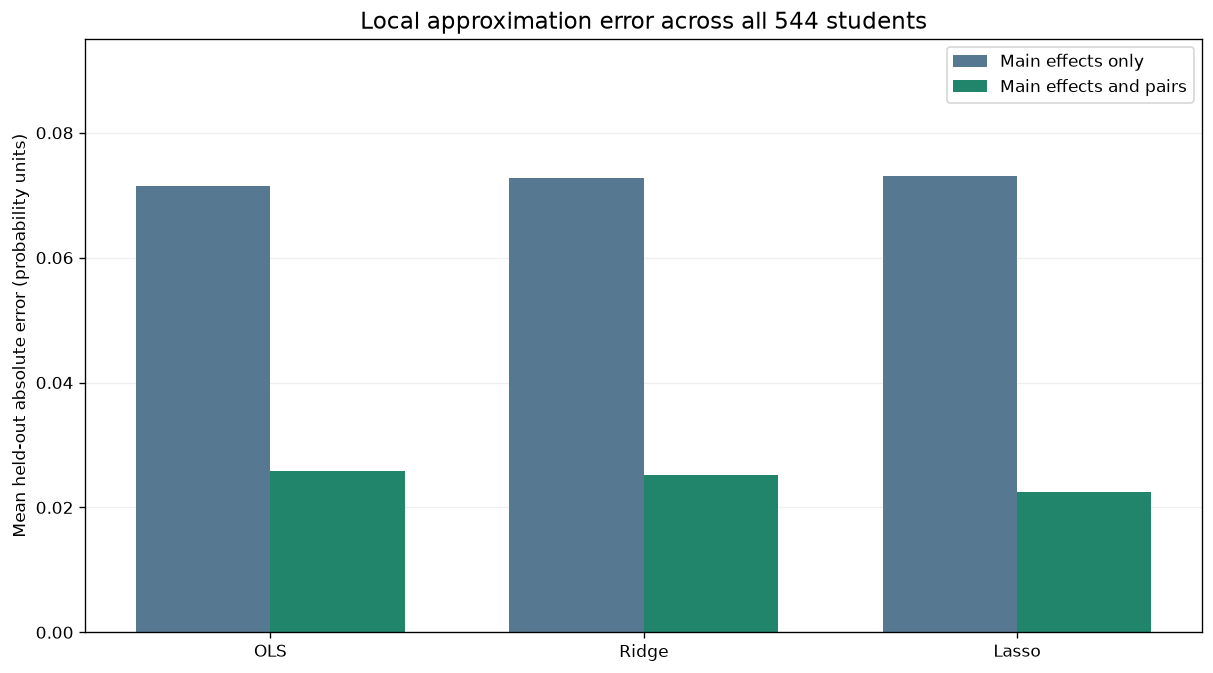

In [5]:
variants = analysis["surrogates"]["variant_summary"]
contrasts = analysis["surrogates"]["main_vs_pairs"]
display(variants)
display(contrasts)
x = np.arange(len(contrasts))
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.bar(x-.18, contrasts["main_only_mae"], .36, label="Main effects only", color="#567991")
ax.bar(x+.18, contrasts["with_pairs_mae"], .36, label="Main effects and pairs", color="#20856b")
ax.set_xticks(x, contrasts["family"])
ax.set_ylabel("Mean held-out absolute error (probability units)")
ax.set_title("Local approximation error across all 544 students")
ax.set_ylim(0, float(contrasts["main_only_mae"].max())*1.3)
ax.legend()
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
fig.savefig(TOPICS / "w1_2_single_vs_pairs/results/main_vs_pairs.png", dpi=160, bbox_inches="tight")
plt.show()

### W1.2 — Single and joint masking responses

The table compares the same pair on the same students. A/B and B/A are combined consistently. A negative joint-minus-best-single value means joint masking changed the probability less than the strongest single mask; nonadditivity can still be important for approximation. Larger masking changes do not mean a better human action.

In [6]:
pair_summary = analysis["pairs"]["summary"]
display(pair_summary.loc[pair_summary["eligible_for_panel"],
    ["group_a", "group_b", "cases_observed", "mean_abs_single_a_change", "mean_abs_single_b_change",
     "mean_abs_joint_change", "mean_abs_nonadditivity", "mean_joint_gain_over_best_single",
     "gain_ci_lower_95", "gain_ci_upper_95"]].head(10))

,group_a,group_b,cases_observed,mean_abs_single_a_change,mean_abs_single_b_change,mean_abs_joint_change,mean_abs_nonadditivity,mean_joint_gain_over_best_single,gain_ci_lower_95,gain_ci_upper_95
120,first_semester_participation,first_semester_progress,360,0.096217,0.306344,0.263812,0.185930,-0.093846,-0.116940,-0.070346
140,first_semester_progress,scholarship_holder,169,0.221933,0.039948,0.322772,0.116593,0.081458,0.058482,0.104101
82,debtor,first_semester_progress,90,0.036693,0.249519,0.306497,0.074245,0.046790,0.019070,0.073908
62,curricular_units_1st_sem_credited,first_semester_progress,30,0.046905,0.330916,0.278676,0.068297,-0.055291,-0.091458,-0.014031
139,first_semester_progress,previous_qualification_grade,67,0.250336,0.047604,0.300845,0.051391,0.032832,0.012166,0.052048
142,first_semester_progress,unemployment_rate,61,0.397582,0.022548,0.397958,0.050531,-0.000012,-0.017592,0.018148
141,first_semester_progress,tuition_fees_up_to_date,457,0.300010,0.030678,0.363567,0.050254,0.048068,0.034567,0.062492
96,displaced,first_semester_progress,110,0.022443,0.301900,0.322504,0.043402,0.017568,0.004364,0.031142
47,course,first_semester_progress,392,0.029049,0.306667,0.328141,0.039202,0.014132,0.005748,0.022886
129,first_semester_participation,scholarship_holder,85,0.142509,0.042787,0.176514,0.036915,0.025025,0.011559,0.039646


## W1.3 — Robustness and numerical boundary handling

Original warning flags are preserved. The second count applies a 1e-12 tolerance at the 0.80 boundary; tiny floating-point differences at 0.80 are not described as material instability. Feature retention below is conditional on cases where that group appeared in the baseline top five.

,variation,students,mean_top5_overlap,original_warning_cases,materially_below_threshold_cases,at_threshold_cases
0,background,544,0.745131,411,403,10
1,perturbation,544,0.995880,0,0,0
2,seed,544,0.817516,213,194,21


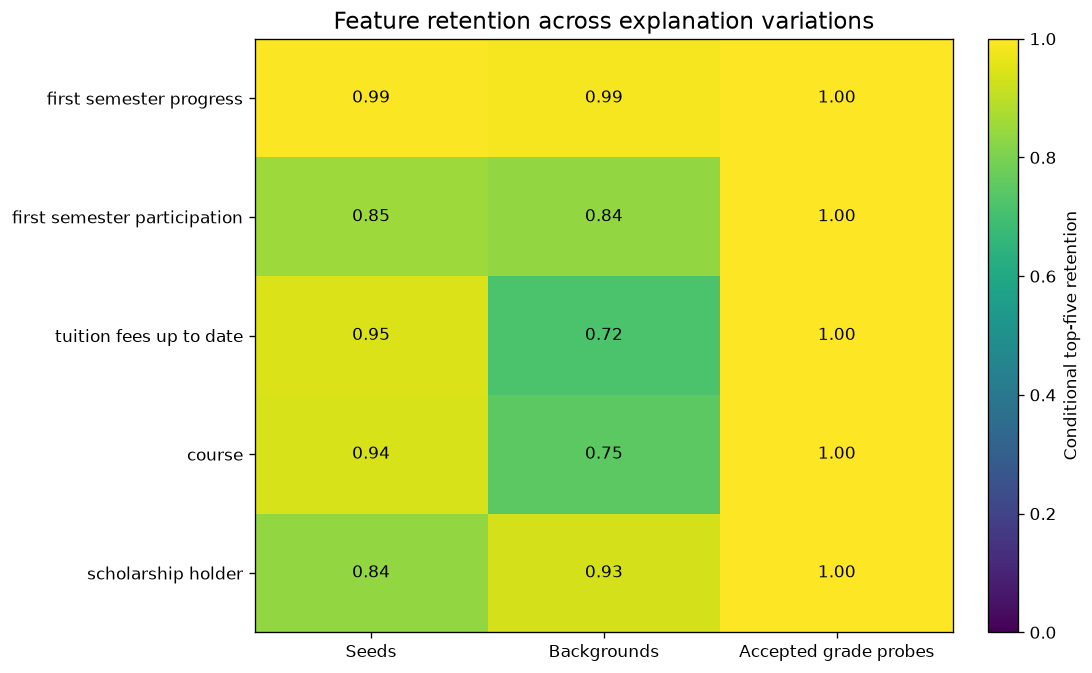

In [7]:
display(analysis["stability"]["overall"])
retention = analysis["stability"]["group_retention"]
selected_names = [r["feature_group"] for r in analysis["selection"]["selected_main_groups"]]
matrix = retention.pivot(index="feature_group", columns="variation", values="conditional_top5_retention")
matrix = matrix.reindex(selected_names)[["seed", "background", "perturbation"]]
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
image = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax.set_yticks(range(len(matrix)), [s.replace("_", " ") for s in matrix.index])
ax.set_xticks(range(3), ["Seeds", "Backgrounds", "Accepted grade probes"])
ax.set_title("Feature retention across explanation variations")
for i in range(len(matrix)):
    for j in range(3):
        v = matrix.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="black" if v>.6 else "white")
fig.colorbar(image, ax=ax, label="Conditional top-five retention")
fig.savefig(TOPICS / "w1_3_robustness/results/selected_feature_retention.png", dpi=160, bbox_inches="tight")
plt.show()

## W1.4 — If features change, what happens to the model result?

These are **previously computed predictions**, not changes inferred by subtracting SHAP. All 2,508 broad rows are preserved, including 544 original profiles. The summary excludes originals. Each scenario has a different eligible population because unchanged/inconsistent edits were skipped; compare before/after within students, not programme effectiveness across scenario means.

A change in an outreach flag only means moving out of the top-20% capacity set, with the other 543 probabilities fixed. It is not a universal risk threshold or an observed dropout prevented. The selected student's recorded values below show exactly which grade, approved-unit, tuition or debtor fields changed.

In [8]:
scenario_summary = analysis["scenarios"]["summary"]
summary_view = scenario_summary[["scenario", "evidence_type", "students_tested", "mean_probability_before",
                                  "mean_probability_after", "mean_change_percentage_points", "students_flagged_before",
                                  "students_leaving_flagged_group"]].copy()
summary_view["mean_probability_before"] *= 100
summary_view["mean_probability_after"] *= 100
summary_view = summary_view.rename(columns={"mean_probability_before": "Mean probability before (%)",
                                           "mean_probability_after": "Mean probability after (%)"})
display(HTML(summary_view.round(3).to_html(index=False, classes="w1-readable", escape=True)))
selected_scenarios = analysis["scenarios"]["by_case"]
selected_scenarios = selected_scenarios.loc[selected_scenarios.source_row_id == CASE_ID].copy()
def changed_inputs(row):
    fields = [("grade /20", "grade"), ("approved units", "approved_units"),
              ("tuition up-to-date (1=yes)", "tuition_paid"), ("debtor (1=yes)", "debtor")]
    return "; ".join(f"{label}: {row['original_'+key]:g} → {row['new_'+key]:g}"
                     for label, key in fields if row['original_'+key] != row['new_'+key]) or "Original profile; no edit"
case_view = pd.DataFrame({"Scenario": selected_scenarios.scenario,
    "Changed inputs": selected_scenarios.apply(changed_inputs, axis=1),
    "Before (%)": 100*selected_scenarios.original_probability,
    "After (%)": 100*selected_scenarios.scenario_probability,
    "Change (percentage points)": selected_scenarios.change_probability_points,
    "Flag after": selected_scenarios.flagged_after})
display(HTML(case_view.round(3).to_html(index=False, classes="w1-readable", escape=True)))
admin = analysis["scenarios"]["administrative_by_case"]
display(Markdown("**Separate saved administrative recourse enumeration:** placeholders for unflagged/no-eligible-change students are retained, but are not evaluated changes."))
display(admin.loc[admin.source_row_id == CASE_ID,
    ["changed_features", "status", "original_probability", "scenario_probability", "change_probability_points", "is_evaluated_change"]].round(4))

scenario,evidence_type,students_tested,Mean probability before (%),Mean probability after (%),mean_change_percentage_points,students_flagged_before,students_leaving_flagged_group
Academic measures + both finance statuses,Historical input sensitivity,495,37.191,20.049,-17.143,83,63
Approved units +2 (historical input what-if),Historical input sensitivity,272,60.716,44.043,-16.673,83,39
Grade +3 AND approved units +2,Historical input sensitivity,495,37.191,25.099,-12.092,83,47
Grade +3/20 (historical input what-if),Historical input sensitivity,441,29.526,26.671,-2.855,30,10
Resolve debtor status,Status-resolution simulation; verify feasibility,62,81.076,74.784,-6.292,30,3
Resolve overdue tuition status,Status-resolution simulation; verify feasibility,85,93.156,76.255,-16.901,51,16
Resolve tuition AND debtor statuses,Status-resolution simulation; verify feasibility,114,85.272,67.418,-17.854,58,17


Scenario,Changed inputs,Before (%),After (%),Change (percentage points),Flag after
Original profile,Original profile; no edit,99.584,99.584,0.000,1
Grade +3/20 (historical input what-if),grade /20: 11.75 → 14.75,99.584,98.945,-0.639,1
Approved units +2 (historical input what-if),approved units: 4 → 6,99.584,91.781,-7.802,0
Grade +3 AND approved units +2,grade /20: 11.75 → 14.75; approved units: 4 → 6,99.584,81.794,-17.789,0
Resolve overdue tuition status,tuition up-to-date (1=yes): 0 → 1,99.584,92.905,-6.679,0
Resolve debtor status,debtor (1=yes): 1 → 0,99.584,98.669,-0.915,0
Resolve tuition AND debtor statuses,tuition up-to-date (1=yes): 0 → 1; debtor (1=yes): 1 → 0,99.584,68.879,-30.705,0
Academic measures + both finance statuses,grade /20: 11.75 → 14.75; approved units: 4 → 6; tuition up-to-date (1=yes): 0 → 1; debtor (1=yes): 1 → 0,99.584,4.201,-95.383,0


**Separate saved administrative recourse enumeration:** placeholders for unflagged/no-eligible-change students are retained, but are not evaluated changes.

,changed_features,status,original_probability,scenario_probability,change_probability_points,is_evaluated_change
15,debtor,leaves_flagged_group,0.9958,0.9867,-0.9147,True
16,tuition_fees_up_to_date,leaves_flagged_group,0.9958,0.9290,-6.6786,True
17,"debtor, tuition_fees_up_to_date",leaves_flagged_group,0.9958,0.6888,-30.7049,True


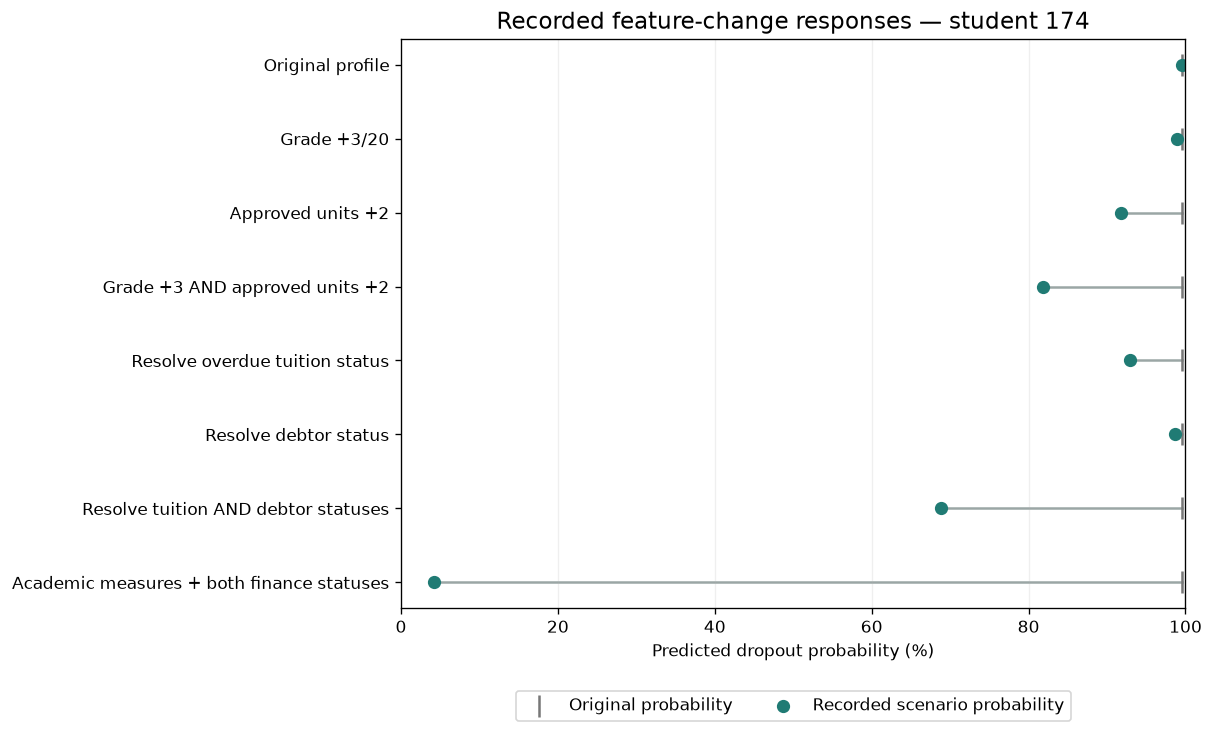

Historical academic edits describe retrospective sensitivity. Finance-status edits require actual support/record verification. Neither estimates what an intervention will do to the student's actual outcome.

In [9]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
labels = selected_scenarios.scenario.str.replace(" (historical input what-if)", "", regex=False)
y = np.arange(len(labels))
ax.scatter(100*selected_scenarios.original_probability, y, color="#777777", marker="|", s=180, label="Original probability")
ax.scatter(100*selected_scenarios.scenario_probability, y, color="#207b74", s=48, label="Recorded scenario probability")
for i, row in enumerate(selected_scenarios.itertuples()):
    ax.plot([100*row.original_probability, 100*row.scenario_probability], [i, i], color="#9ba6a5", zorder=0)
ax.set_yticks(y, labels); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Predicted dropout probability (%)")
ax.set_title(f"Recorded feature-change responses — student {CASE_ID}")
ax.grid(axis="x", alpha=.2); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.13), ncol=2)
fig.savefig(TOPICS / "w1_4_human_support/results/selected_case_scenarios.png", dpi=160, bbox_inches="tight")
plt.show()
display(Markdown("Historical academic edits describe retrospective sensitivity. Finance-status edits require actual support/record verification. Neither estimates what an intervention will do to the student's actual outcome."))

### Optional: predict a new feature edit using your already-fitted model

The saved scenarios cover four editable inputs, not every possible change to all 33 columns. The helper below makes a small batch of new predictions only when you call it. It does not train, download, run SHAP or write audit files. Use the same fitted TabICL context and original model columns to compare with the recorded audit. If your kernel has no fitted model, these arbitrary new edits cannot be predicted from the saved case JSON alone.

Use an original feature row from `VALIDATION`, not the case JSON. Historical grade/approved-unit edits require `allow_retrospective=True`. Administrative records must represent verified resolutions before operational use. New scores do not automatically update saved cohort flags.

In [10]:
from w1_4_human_support.scenarios import predict_feature_changes

def score_new_changes(model, original_feature_row, feature_columns, scenarios, *, allow_retrospective=False):
    from src.modeling import prepare_tfm_frame
    if list(model.classes_) != [0, 1]:
        raise ValueError("Expected Graduate=0, Dropout=1.")
    def predict_dropout(frame):
        return model.predict_proba(prepare_tfm_frame(frame, feature_columns))[:, 1]
    return predict_feature_changes(original_feature_row, scenarios, predict_dropout,
                                   allow_retrospective=allow_retrospective)

# In the ORIGINAL runnable notebook, after MODEL is fitted, for a student with an eligible debt/tuition change:
# row = VALIDATION.loc[VALIDATION["source_row_id"] == CASE_ID].iloc[0]
# display(score_new_changes(MODEL, row, FEATURE_COLUMNS,
#     {"Both finance statuses verified resolved": {"debtor": 0, "tuition_fees_up_to_date": 1}}))
# Results are new model predictions, not estimates of prevented dropouts.
print("Optional helper defined. No model predictions, model fitting or audit computations were run.")

Optional helper defined. No model predictions, model fitting or audit computations were run.


## W1.4 — Human actions aimed at continued enrollment

The old 17/108 figure concerns changes to a model flag under a narrow debt/tuition experiment. It does not measure actual dropout prevention. The proposals below target confirmed current barriers, future course progress and support access. Historical first-semester grades are not prospectively editable.

Use one coordinating adviser, agree priorities with the student, and monitor future enrollment/completion. Unflagged students should retain access to support and self-referral. Model signals are review prompts; they do not establish a student's need or programme eligibility.

In [11]:
from w1_4_human_support.analysis import make_support_plan
plan = make_support_plan(selected_case)
catalogue = analysis["support"]["catalogue"]
display(Markdown(f"**Student {CASE_ID}: proposed review prompts; ask the student to confirm needs first.**"))
display(HTML(catalogue.loc[catalogue.code.isin(plan["proposed_support_codes"]),
    ["code", "verification_question", "human_action", "student_action", "follow_up"]]
    .to_html(index=False, classes="w1-readable", escape=True)))
display(Markdown("**Then agree an action plan:** a named adviser confirms barriers and preferences; the tutor arranges future learning support, the finance office checks assistance/payment options, and staff coordinate both when both needs are confirmed. Review support delivery and future enrollment/progress. The proposed two-week review is a planning default, not an evaluated intervention dose."))
display(HTML("<style>.w1-support td{white-space:normal;max-width:340px;vertical-align:top}</style>" +
    catalogue[["code", "owner", "human_action", "outcome_to_monitor"]].to_html(index=False, classes="w1-support", escape=True)))
display(Markdown((TOPICS / "w1_4_human_support/README.md").read_text()))
display(Markdown("The empty future-retention follow-up CSV is available beside the human-support code. No intervention assignments or future outcomes were observed in this audit."))

**Student 174: proposed review prompts; ask the student to confirm needs first.**

code,verification_question,human_action,student_action,follow_up
adviser_check_in,"What is making continued study difficult, and what support does the student want?",Agree a confidential support plan and one named contact; keep self-referral open to unflagged students.,Choose priorities and preferred contact method; participation is voluntary.,Proposed first contact within one week; agree a review after two weeks.
academic_support,"Which future course skills, assignments or study arrangements need support?","Arrange targeted tutoring, an attainable study plan and instructor-approved catch-up options.",Agree achievable weekly study/assignment goals and attend suitable support sessions.,Review engagement and future-course progress after two weeks.
financial_support,"Are tuition, food, transport, books, caring costs or registration holds genuine barriers?","Check grant/bursary eligibility, emergency assistance, permitted payment plans and registration-hold resolution.",Choose acceptable assistance and provide only information needed for eligibility checks.,Review before relevant payment/registration deadlines.
engagement_support,"Are work, caring, transport, timetable, accessibility or wellbeing barriers limiting participation?",Discuss feasible scheduling/accessibility arrangements and voluntary referral to relevant services.,Identify practical barriers and choose a manageable participation plan.,Agree a short review cycle; avoid repeated contacts that add burden.
course_fit_support,"Does the programme, timetable or workload fit the student’s goals and circumstances?","Discuss feasible timetable, programme or workload options; check funding and programme rules before changes.",Choose suitable options with an adviser rather than changing records to lower a score.,Review before programme/timetable deadlines.
academic_financial_bundle,Has the student confirmed both academic and financial barriers?,"Coordinate tutoring and practical financial assistance in one plan, with one follow-up contact.",Agree the combined plan and say whether either component creates extra burden.,"Proposed weekly check-ins initially, adjusted to student preference and need."
academic_engagement_bundle,Has the student confirmed both learning and participation barriers?,Combine targeted tutoring with practical attendance/timetable support in one manageable plan.,"Agree realistic study and participation goals, adapted to circumstances.",Review progress and burden after two weeks.
engagement_financial_bundle,Has the student confirmed that affordability is limiting participation?,Coordinate feasible financial assistance with access/timetable arrangements.,Choose assistance that addresses the actual barrier.,Review assistance delivery and participation before relevant deadlines.


**Then agree an action plan:** a named adviser confirms barriers and preferences; the tutor arranges future learning support, the finance office checks assistance/payment options, and staff coordinate both when both needs are confirmed. Review support delivery and future enrollment/progress. The proposed two-week review is a planning default, not an evaluated intervention dose.

code,owner,human_action,outcome_to_monitor
adviser_check_in,Named student adviser,Agree a confidential support plan and one named contact; keep self-referral open to unflagged students.,"Support uptake, unresolved barriers, continued enrollment and completion."
academic_support,Adviser and course tutor,"Arrange targeted tutoring, an attainable study plan and instructor-approved catch-up options.","Future submissions, attendance, credits earned and continued enrollment."
financial_support,Financial-aid adviser,"Check grant/bursary eligibility, emergency assistance, permitted payment plans and registration-hold resolution.","Support received, barriers resolved, registration and continued enrollment."
engagement_support,Student adviser and course staff,Discuss feasible scheduling/accessibility arrangements and voluntary referral to relevant services.,"Future participation, submissions, barrier resolution and continued enrollment."
course_fit_support,Programme adviser,"Discuss feasible timetable, programme or workload options; check funding and programme rules before changes.","Agreed study plan, course engagement, transfer/completion/enrollment status."
academic_financial_bundle,One coordinating adviser plus tutor and aid adviser,"Coordinate tutoring and practical financial assistance in one plan, with one follow-up contact.","Both barriers, support uptake and future enrollment/completion; not a change in model flag."
academic_engagement_bundle,One coordinating adviser and course tutor,Combine targeted tutoring with practical attendance/timetable support in one manageable plan.,"Future submissions, credits, participation and continued enrollment."
engagement_financial_bundle,Student adviser and financial-aid adviser,Coordinate feasible financial assistance with access/timetable arrangements.,"Barrier resolution, attendance and continued enrollment/completion."


# W1.4 — Human support to improve the opportunity to remain enrolled

`analysis.py` creates a support catalogue and case review prompts. It does not estimate how many dropouts an action prevents. Confirmed student needs and preferences take precedence over SHAP signals. Protected/background attributes do not become instructions to change the student. Support remains open to unflagged students.

## Single support options and coordinated pairs

| Confirmed barrier | Practical human action | Coordinated pair to consider |
| --- | --- | --- |
| Learning/course progress | Tutor identifies specific future-course difficulties; agree attainable study and assignment goals. | Academic tutoring + practical engagement support. |
| Participation/access | Adviser asks about timetable, work, caring, transport, accessibility and wellbeing barriers; arrange feasible support/referrals. | Engagement support + financial assistance where affordability is a confirmed barrier. |
| Affordability/registration | Aid adviser checks bursaries, emergency assistance, allowed payment plans and hold resolution. | Academic tutoring + financial-aid coordination where both needs are confirmed. |
| Course fit/workload | Discuss programme/timetable options; check funding and programme requirements before changes. | Personalised academic advising + relevant support chosen with the student. |

Use one coordinating adviser, propose first contact within one week, agree the student's priorities, and review after two weeks. Timelines are operational suggestions, not model-derived rules. Historical first-semester grades cannot be changed prospectively; target future study conditions, engagement and completion.

The original financial-status recourse moved 17 of 108 flagged students out of the model's capacity set. Fifty flagged students had no available tuition/debt change under that restricted test. These counts measure a model experiment, not the effectiveness of human support.

## Measure the actual outcome

The empty `results/future_retention_follow_up_template.csv` records confirmed needs, support offered/accepted and later enrollment/completion. Record baseline information before support. Do not use later support/outcome variables as baseline predictors. Distinguish graduation, approved leave and transfer from dropout, and agree the outcome window before evaluation.

To compare real single and combined supports, evaluate additional academic support, additional financial/navigation support, both, and usual available support in a prospective design appropriate to the institution. Standard necessary services should remain available. This audit does not select a causally best intervention arm or assign students to a programme.

## Evidence informing proposals

- [What Works Clearinghouse: Effective Advising for Postsecondary Students](https://ies.ed.gov/ncee/wwc/PracticeGuide/28) recommends comprehensive integrated academic/non-academic advising, sustained personalised relationships, mentoring and coaching.
- [MDRC: Doubling Graduation Rates](https://www.mdrc.org/work/publications/doubling-graduation-rates) reports a randomized evaluation of CUNY ASAP's comprehensive programme, including advising, tutoring and financial supports. Its three-year degree results were 40% versus 22% in that setting. This is evidence about that programme bundle, not an estimate for this institution or isolated proof that a particular pair of supports is best.

Current data contain no intervention assignments or future retention outcomes. The support options are student-confirmed proposals requiring local evaluation, not guaranteed prevention.

## Read in this order

1. `w1_1_local_explanations/feature_guide.py` defines all 33 model inputs; `results/all_33_feature_definitions.csv` lists meanings and action context. `explain_case(record)` shows all 27 signed contributions for a selected student. Positive means a higher model probability relative to the SHAP background; negative means a lower probability. The two academic groups have only group totals saved, so separate contributions for their members are unavailable.
2. `w1_4_human_support/scenarios.py` validates saved before/after probabilities and exports `results/recorded_scenario_summary.csv`. All 2,508 broad rows and 590 administrative rows remain in the case exports inside the full ZIP. Original/no-change rows are not effect experiments. The scenario cohorts differ; this is not an intervention-efficacy ranking.
3. `make_support_plan(record)` proposes human review and practical support; use confirmed needs to choose single or combined assistance. Historical grade/credit edits are not prospective actions. Monitor future enrollment and progress rather than treating a flag change as success.

The executed W1 notebook provides the full sequence, a named-case example and an optional prediction-only wrapper for new four-input edits. The optional function needs an already-fitted model, does not fit/download anything and never overwrites audit evidence. Other feature edits were not exhaustively simulated in the recorded scenarios; their SHAP/masking contributions are not substitutes for a new prediction.


The empty future-retention follow-up CSV is available beside the human-support code. No intervention assignments or future outcomes were observed in this audit.

## W1.5 — Selected explanatory panel

The transparent reporting policy chooses five high-importance groups, then up to three supported pairs within them if pair-augmented surrogates have lower recorded holdout error. This is not a causal feature ranking or a newly validated predictor input set. Convergence warnings and instability remain relevant.

Exact nonzero Lasso coefficient identities were not saved in the original case format. The panel does not invent them.

In [12]:
selection = analysis["selection"]
display(pd.DataFrame(selection["selected_main_groups"]))
display(pd.DataFrame(selection["selected_pairs"]))
display(pd.DataFrame({"Selected model columns for explanation": selection["selected_model_columns"]}))
display(Markdown("**Scope:** explanatory reporting only. **Prediction model changed:** False. **Status:** provisional explanatory panel."))
display(Markdown("For a new predictor's final inputs, use separate training-only selection and evaluation; those are different claims from the saved masking audit."))

,feature_group,cases_observed,members,mean_absolute_group_shap,median_absolute_group_shap,mean_signed_group_shap,fraction_raising_prediction,fraction_lowering_prediction,baseline_top5_fraction
0,first_semester_progress,544,"curricular_units_1st_sem_approved, curricular_...",0.276915,0.272528,0.016900,0.430147,0.569853,0.965074
1,first_semester_participation,544,"curricular_units_1st_sem_enrolled, curricular_...",0.052526,0.031998,0.000904,0.555147,0.444853,0.683824
2,tuition_fees_up_to_date,544,tuition_fees_up_to_date,0.051317,0.033974,-0.004326,0.156250,0.843750,0.869485
3,course,544,course,0.041828,0.041652,-0.021924,0.266544,0.733456,0.746324
4,scholarship_holder,544,scholarship_holder,0.019297,0.010685,-0.003059,0.750000,0.250000,0.321691


,group_a,group_b,cases_observed,eligible_for_panel,mean_abs_single_a_change,mean_abs_single_b_change,mean_abs_joint_change,mean_abs_nonadditivity,mean_signed_nonadditivity,mean_joint_gain_over_best_single,gain_ci_lower_95,gain_ci_upper_95,joint_exceeds_each_single_fraction
0,first_semester_participation,first_semester_progress,360,True,0.096217,0.306344,0.263812,0.185930,-0.110014,-0.093846,-0.116940,-0.070346,0.327778
1,first_semester_progress,scholarship_holder,169,True,0.221933,0.039948,0.322772,0.116593,0.097783,0.081458,0.058482,0.104101,0.591716
2,first_semester_progress,tuition_fees_up_to_date,457,True,0.300010,0.030678,0.363567,0.050254,-0.041997,0.048068,0.034567,0.062492,0.161926


,Selected model columns for explanation
0,course
1,curricular_units_1st_sem_approved
2,curricular_units_1st_sem_enrolled
3,curricular_units_1st_sem_evaluations
4,curricular_units_1st_sem_grade
5,curricular_units_1st_sem_without_evaluations
6,first_semester_no_enrollment
7,first_semester_no_evaluations
8,first_semester_pass_rate
9,scholarship_holder


**Scope:** explanatory reporting only. **Prediction model changed:** False. **Status:** provisional explanatory panel.

For a new predictor's final inputs, use separate training-only selection and evaluation; those are different claims from the saved masking audit.

## Interpretation and files

Pair-aware surrogates improve fidelity to the recorded model under held-out masking tests. Academic/financial/engagement support combinations are proposals requiring human confirmation and prospective evaluation; their actual dropout effects cannot be ranked from masking responses.

Each W1 topic contains `analysis.py`, a README and its `results/` folder. `W1_SUMMARY.md` records the comparison, reporting policy and limits. All original 544 case files and source model settings remain unchanged. The original uploaded notebook and its outputs are preserved separately.